### **Short-Term Memory with the InMemorySaver**

#### Set the OpenAI API Key as an Environment Variable

In [1]:
%load_ext dotenv
%dotenv
%load_ext mypy_ipython

#### Import Relevant Classes and Functions

In [2]:
from langgraph.graph import START, END, StateGraph, MessagesState
from langchain_openai.chat_models import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage, RemoveMessage, BaseMessage
from langgraph.checkpoint.memory import InMemorySaver

#### Define the State

In [3]:
class State(MessagesState):
    summary: str

#### Define the Nodes

In [4]:
chat = ChatOpenAI(
    model = "gpt-4o",
    seed = 7,
    temperature = 0,
    max_completion_tokens = 100
)

In [5]:
def ask_question(state: State) -> State:

    print(f"\n------> ENTERING ask_question:")

    question = "What is your question?"
    print(question)

    return State(messages = [AIMessage(question), HumanMessage(input())])

In [6]:
def chatbot(state: State) -> State:

    print(f"\n------> ENTERING chatbot:")

    system_message = f'''
        Here's a quick summary of what's been discussed so far:
        {state.get("summary", "")}

        Keep this in mind as you answer the next question.
    '''
    
    response = chat.invoke([SystemMessage(system_message)] + state["messages"])
    response.pretty_print()

    return State(messages = [response])

In [7]:
def summarize_messages(state: State) -> State:
    print(f"\n------> ENTERING summarize_messages:")

    new_conversation = ""
    for i in state["messages"]:
        new_conversation += f"{i.type}: {i.content}\n\n"

    summary_instructions = f'''
        Update the ongoing summary by incorporating the new lines of conversation below.
        Build upon the previous summary rather than repeating it so that the result reflects the most recent context and developments.

        Previous summary:
        {state.get("summary", "")}

        New Conversation:
        {new_conversation}
    '''

    print(summary_instructions)

    summary = chat.invoke([HumanMessage(summary_instructions)])

    remove_messages = [RemoveMessage(id = i.id) for i in state["messages"][:]]

    return State(messages = remove_messages, summary = summary.content)

#### Define the Graph

In [8]:
graph = StateGraph(State)

In [9]:
graph.add_node("ask_question", ask_question)
graph.add_node("chatbot", chatbot)
graph.add_node("summarize_messages", summarize_messages)

graph.add_edge(START, "ask_question")
graph.add_edge("ask_question", "chatbot")
graph.add_edge("chatbot", "summarize_messages")
graph.add_edge("summarize_messages", END)

In [12]:
checkpinter = InMemorySaver()
graph_compiled = graph.compile(checkpinter)

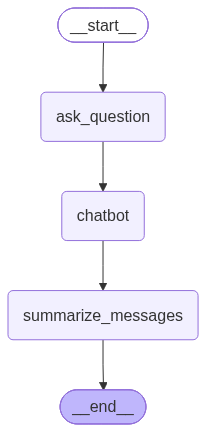

In [13]:
graph_compiled

In [18]:
config1 = {"configurable": {"thread_id": "1"}}
config2 = {"configurable": {"thread_id": "2"}}

In [19]:
graph_compiled.invoke(State(), config2)


------> ENTERING ask_question:
What is your question?


 When took it place?



------> ENTERING chatbot:
================================== Ai Message ==================================

Could you please provide more context or specify what event or topic you are referring to?

------> ENTERING summarize_messages:

        Update the ongoing summary by incorporating the new lines of conversation below.
        Build upon the previous summary rather than repeating it so that the result reflects the most recent context and developments.

        Previous summary:
        

        New Conversation:
        ai: What is your question?

human: When took it place?

ai: Could you please provide more context or specify what event or topic you are referring to?


    


{'messages': [],
 'summary': 'Previous summary: The conversation is in its early stages, with the AI asking the human for their question.\n\nUpdated summary: The human asked about the timing of an unspecified event, prompting the AI to request more context or clarification regarding the event or topic in question.'}

In [20]:
graph_compiled.invoke(State(), config1)


------> ENTERING ask_question:
What is your question?


 When took it place?



------> ENTERING chatbot:
================================== Ai Message ==================================

The 1990 FIFA World Cup took place from June 8 to July 8, 1990.

------> ENTERING summarize_messages:

        Update the ongoing summary by incorporating the new lines of conversation below.
        Build upon the previous summary rather than repeating it so that the result reflects the most recent context and developments.

        Previous summary:
        Updated summary:

The human inquired about the winner of the 1990 FIFA World Cup, and the AI informed them that West Germany won by defeating Argentina 1-0 in the final match. The human then asked where the tournament took place, and the AI explained that the 1990 FIFA World Cup was held in Italy from June 8 to July 8, with matches played in various cities. The final match occurred at the Stadio Olimpico in Rome. The human further asked who

        New Conversation:
        ai: What is your question?

human: When took it p

{'messages': [],
 'summary': 'Updated summary:\n\nThe human inquired about the winner of the 1990 FIFA World Cup, and the AI informed them that West Germany won by defeating Argentina 1-0 in the final match. The human then asked where the tournament took place, and the AI explained that the 1990 FIFA World Cup was held in Italy from June 8 to July 8, with matches played in various cities. The final match occurred at the Stadio Olimpico in Rome. The human further asked when'}

In [23]:
graph_states = [i for i in graph_compiled.get_state_history(config1)]

In [26]:
for i in graph_states[::-1]:
    print(
        f'''
            Messages: {i.values["messages"]}
            Summary: {i.values.get("summary", "")}
            Next: {i.next}
            Step: {i.metadata["step"]}
        '''
    )


            Messages: []
            Summary: 
            Next: ('__start__',)
            Step: -1
        

            Messages: []
            Summary: 
            Next: ('ask_question',)
            Step: 0
        

            Messages: [AIMessage(content='What is your question?', additional_kwargs={}, response_metadata={}, id='fca54e32-43ca-48ca-8d8d-aa563d329b92', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='Who won the FIFA World Cup 1990?', additional_kwargs={}, response_metadata={}, id='7fd4ac9e-7580-4266-9f2b-c7a538af66b9')]
            Summary: 
            Next: ('chatbot',)
            Step: 1
        

            Messages: [AIMessage(content='What is your question?', additional_kwargs={}, response_metadata={}, id='fca54e32-43ca-48ca-8d8d-aa563d329b92', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='Who won the FIFA World Cup 1990?', additional_kwargs={}, response_metadata={}, id='7fd4ac9e-7580-4266-9f2b-c7a538af66b9'), AIMessage(conten

### Restarting the notebook's kernel results in memory loss **!!!**